# CardioIA — Fase 2 | Parte 2: classificador de risco na triagem

Este notebook treina um classificador de texto que lê uma frase escrita pelo paciente e a separa em **alto risco** ou **baixo risco**, simulando a fila de prioridade de uma triagem clínica.

O caminho é o pedido no enunciado: base rotulada em CSV, vetorização por **TF-IDF**, um modelo simples do Scikit-learn, avaliação por acurácia e análise de como o modelo se comporta diante de frases de risco diferente.

**Aluno:** Diego Filipe Pereira de Araujo — RM567064

## 1. A base rotulada

A base está em [`../dados/frases_risco.csv`](../dados/frases_risco.csv), com duas colunas: `frase` e `situacao`. São 72 frases curtas escritas em linguagem de paciente, metade de cada classe.

O vocabulário segue a terminologia em português brasileiro dos textos coletados na Fase 1, e não traduções do inglês — "aperto no peito" e "falta de ar" são as expressões que realmente aparecem num atendimento no Brasil.

In [1]:
import pandas as pd

dados = pd.read_csv("../dados/frases_risco.csv")

print("Frases:", len(dados))
print(dados["situacao"].value_counts().to_string())
dados.head(8)

Frases: 72
situacao
alto risco     36
baixo risco    36


,frase,situacao
0,sinto dor no peito e falta de ar ao mesmo tempo,alto risco
1,dor forte no peito que irradia para o braço es...,alto risco
2,acordei com aperto no peito e suor frio,alto risco
3,estou com falta de ar mesmo em repouso,alto risco
4,desmaiei hoje enquanto caminhava na rua,alto risco
5,meu coração está disparado e sinto tontura,alto risco
6,dor no peito que não passa há mais de uma hora,alto risco
7,sinto o peito pesado e não consigo respirar fundo,alto risco


A base está equilibrada (36 por classe). Isso é uma escolha, não um acaso: com classes desbalanceadas, um modelo que respondesse sempre a classe majoritária já acertaria a maior parte dos casos e a acurácia esconderia o problema.

## 2. TF-IDF: da frase para o vetor

O algoritmo não entende texto, então cada frase precisa virar uma lista de números. O **TF-IDF** (*term frequency – inverse document frequency*) faz isso dando a cada termo um peso que combina duas ideias:

- **TF** — quantas vezes o termo aparece na frase;
- **IDF** — quão raro ele é no conjunto todo.

Um termo que aparece em quase todas as frases é pouco informativo e recebe peso baixo; um termo que aparece em poucas frases recebe peso alto. É o que interessa numa triagem: o que distingue um caso é o termo incomum.

Dois parâmetros foram ajustados:

- `ngram_range=(1, 2)` — além de palavras isoladas, o vetorizador considera pares de palavras vizinhas. Isso importa porque "falta de ar" e "dor no peito" só têm sentido clínico como expressão; separadas, perdem o significado.
- `min_df=2` — o termo precisa aparecer em pelo menos duas frases para entrar no vocabulário. Sem isso, qualquer palavra escrita uma única vez ganharia o IDF máximo e viraria uma pista única daquela frase, o que o modelo decoraria em vez de aprender.

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

vetorizador = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
X = vetorizador.fit_transform(dados["frase"])
y = dados["situacao"]
termos = vetorizador.get_feature_names_out()

print("Matriz TF-IDF:", X.shape)
print("Termos no vocabulario:", len(termos))

Matriz TF-IDF: (72, 140)
Termos no vocabulario: 140


In [3]:
indice = 2
pesos = pd.Series(X[indice].toarray()[0], index=termos)

print("Frase:", dados["frase"].iloc[indice], "\n")
print(pesos.sort_values(ascending=False).head(6).to_string())

Frase: acordei com aperto no peito e suor frio 

acordei      0.376083
suor         0.376083
suor frio    0.376083
aperto       0.376083
aperto no    0.376083
frio         0.350273


In [4]:
idf = pd.Series(vetorizador.idf_, index=termos).sort_values()

print("Termos menos informativos (IDF baixo)")
print(idf.head(8).to_string())

Termos menos informativos (IDF baixo)
no          2.071584
de          2.112406
peito       2.245937
sinto       2.294727
um          2.346020
no peito    2.400088
com         2.457246
dor         2.457246


A segunda saída mostra o TF-IDF funcionando: `dor`, `peito` e `no peito` estão entre os termos de menor peso. Num conjunto onde quase todo mundo fala de dor no peito, mencionar dor no peito informa pouco — o que separa os casos é o que vem junto.

A matriz é quase toda de zeros: cada frase usa pouquíssimos dos 140 termos do vocabulário. Essa esparsidade é normal em NLP e é o que torna o TF-IDF viável em bases pequenas.

## 3. Treino e teste

Separamos 75% das frases para treino e 25% para teste, com `stratify=y` para manter a proporção das classes nos dois lados. Sem isso, com 72 frases, uma divisão aleatória poderia deixar o teste quase todo de uma só classe.

Comparamos dois modelos simples do Scikit-learn: **regressão logística** e **árvore de decisão**.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print("Treino:", X_treino.shape[0], "frases")
print("Teste :", X_teste.shape[0], "frases\n")

modelos = {
    "Regressao Logistica": LogisticRegression(max_iter=1000),
    "Arvore de Decisao": DecisionTreeClassifier(random_state=42),
}

for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    print("{:22s} acuracia = {:.2%}".format(nome, accuracy_score(y_teste, modelo.predict(X_teste))))

Treino: 54 frases
Teste : 18 frases

Regressao Logistica    acuracia = 88.89%
Arvore de Decisao      acuracia = 72.22%


## 4. Avaliação do modelo escolhido

A regressão logística ficou bem à frente da árvore e foi a escolhida. Além do desempenho, ela tem duas vantagens para um sistema de saúde: devolve uma **probabilidade** em vez de um rótulo seco, o que permite calibrar o limiar da triagem, e seus **coeficientes são legíveis** — é possível mostrar quais termos pesaram na decisão. A árvore também é interpretável, mas com texto esparso ela se apoia na presença de poucos termos e decora o treino.

In [6]:
from sklearn.metrics import classification_report, confusion_matrix

modelo = modelos["Regressao Logistica"]
previsto = modelo.predict(X_teste)
indice_alto = list(modelo.classes_).index("alto risco")

print("Acuracia: {:.2%}\n".format(accuracy_score(y_teste, previsto)))
print(classification_report(y_teste, previsto, digits=3))

Acuracia: 88.89%

              precision    recall  f1-score   support

  alto risco      1.000     0.778     0.875         9
 baixo risco      0.818     1.000     0.900         9

    accuracy                          0.889        18
   macro avg      0.909     0.889     0.887        18
weighted avg      0.909     0.889     0.887        18



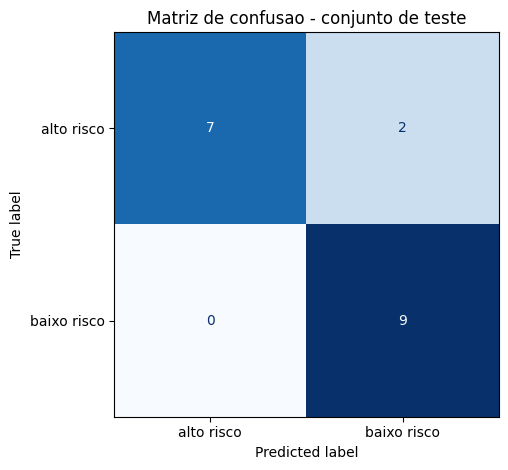

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_teste, previsto, labels=modelo.classes_, cmap="Blues", colorbar=False
)
plt.title("Matriz de confusao - conjunto de teste")
plt.tight_layout()
plt.show()

Aqui o erro que importa não é qualquer erro. Classificar um caso de **baixo risco como alto** gera um atendimento desnecessário; classificar um caso de **alto risco como baixo** manda para o fim da fila alguém que pode estar infartando. Os dois erros não custam a mesma coisa, e a acurácia trata ambos como equivalentes.

É por isso que a métrica a vigiar é o **recall da classe "alto risco"**: 0,778 significa que 2 dos 9 casos graves do teste foram rebaixados. Numa triagem real, esses dois pacientes esperariam.

### Validação cruzada

Com 18 frases no teste, um único acerto a mais ou a menos muda a acurácia em mais de 5 pontos. A validação cruzada em 5 partes usa todas as frases como teste em algum momento e dá uma leitura mais estável.

In [8]:
from sklearn.model_selection import cross_val_score

notas = cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=5, scoring="accuracy")

print("Acuracia por particao:", [round(float(n), 3) for n in notas])
print("Media: {:.2%} (desvio {:.2%})".format(notas.mean(), notas.std()))

Acuracia por particao: [0.933, 0.733, 1.0, 0.929, 0.929]
Media: 90.48% (desvio 8.99%)


### O que o modelo aprendeu

Os coeficientes mostram quais termos empurram a decisão para cada lado. Como `classes_` está em ordem alfabética, o sinal é ajustado para que o valor positivo signifique sempre "alto risco".

In [9]:
sinal = 1 if indice_alto == 1 else -1
coeficientes = pd.Series(modelo.coef_[0] * sinal, index=termos).sort_values()

print("Termos que puxam para BAIXO RISCO")
print(coeficientes.head(10).to_string())
print("\nTermos que puxam para ALTO RISCO")
print(coeficientes.tail(10).to_string())

Termos que puxam para BAIXO RISCO
leve        -0.844896
depois      -0.689761
mas         -0.563283
do          -0.557623
depois de   -0.523062
um          -0.512979
uma         -0.468093
tive        -0.445212
um pouco    -0.416113
pouco       -0.416113

Termos que puxam para ALTO RISCO
falta de    0.416150
para        0.473596
no          0.502135
ar          0.535055
dor         0.565996
desmaiei    0.578337
dor no      0.652905
muito       0.717716
peito       0.738377
no peito    0.765510


Do lado do alto risco aparece conteúdo clínico: `peito`, `dor no`, `falta de`, `ar`, `desmaiei`. Do lado do baixo risco, o termo mais forte é `leve` — e logo atrás vêm `depois`, `mas`, `um`, `uma`, `tive`, `um pouco`, que não descrevem sintoma nenhum. São marcas de **estilo de escrita**: nossas frases brandas tendem ao passado ("tive uma dor...") e ao atenuador ("um pouco"), enquanto as graves estão no presente. O modelo aprendeu esse padrão junto com a gravidade.

## 5. Comportamento diante de frases novas

O teste que vale é com frases que o modelo nunca viu. As quatro últimas são propositalmente difíceis:

- as linhas 3 e 4 são a **mesma frase**, mudando só a palavra "leve";
- a linha 5 mistura um sintoma brando com um sinal de alarme ("falta de ar quando me deito", clássico de insuficiência cardíaca);
- a linha 6 é uma negação.

In [10]:
novas = [
    "sinto uma dor no peito que irradia para o braço e estou suando frio",
    "estou com dor no peito há três horas e com muita falta de ar",
    "tive um leve desconforto no peito depois de correr no parque",
    "dor no peito que irradia para o braço esquerdo",
    "dor leve no peito que irradia para o braço esquerdo",
    "sinto um leve cansaço mas também falta de ar quando me deito",
    "não sinto dor no peito nem falta de ar",
]

X_novas = vetorizador.transform(novas)

pd.set_option("display.max_colwidth", 70)
pd.DataFrame({
    "frase": novas,
    "classificacao": modelo.predict(X_novas),
    "prob_alto_risco": modelo.predict_proba(X_novas)[:, indice_alto].round(3),
})

,frase,classificacao,prob_alto_risco
0,sinto uma dor no peito que irradia para o braço e estou suando frio,alto risco,0.696
1,estou com dor no peito há três horas e com muita falta de ar,alto risco,0.789
2,tive um leve desconforto no peito depois de correr no parque,baixo risco,0.356
3,dor no peito que irradia para o braço esquerdo,alto risco,0.739
4,dor leve no peito que irradia para o braço esquerdo,alto risco,0.617
5,sinto um leve cansaço mas também falta de ar quando me deito,baixo risco,0.420
6,não sinto dor no peito nem falta de ar,alto risco,0.793


## 6. Padrões e distorções observados

As três primeiras frases foram classificadas corretamente e com boa margem. As quatro últimas revelam onde a solução quebra.

**Uma palavra pesa mais que o quadro clínico.** As linhas 3 e 4 descrevem a mesma dor irradiada para o braço esquerdo. Inserir "leve" derruba a probabilidade de alto risco de **0,739 para 0,617**. O rótulo não mudou nesse caso, mas 12 pontos de probabilidade se moveram por causa de um adjetivo — e a dor irradiada continua sendo dor irradiada, com ou sem ele. A base ensinou isso ao modelo: "leve" aparece com muita frequência nas nossas frases de baixo risco, e a correlação virou atalho.

**O atalho chega a errar.** A linha 5 é um erro de verdade: "falta de ar quando me deito" é ortopneia, sinal de alarme de insuficiência cardíaca, mas a frase começa com "um leve cansaço mas" e sai classificada como **baixo risco (0,420)**. Os três termos de maior peso para baixo risco — `leve`, `mas`, `um` — estão todos ali.

**O modelo não entende negação.** A linha 6, `"não sinto dor no peito nem falta de ar"`, é classificada como **alto risco com 0,793**. Para o TF-IDF, "não" é só mais um termo; a estrutura da frase se perde. Modelos de saco de palavras são cegos a negação, e em prontuário médico — onde "nega dor torácica" é construção padrão — isso é um problema sério.

**A base é pequena e artificial.** As 72 frases foram escritas por uma única pessoa, o que produz um vocabulário mais uniforme e mais fácil que o de pacientes reais, que escrevem com erros de digitação, gírias regionais e descrições vagas. A acurácia medida aqui é um limite superior otimista.

### Herança de viés da base da Fase 1

O enunciado pede análise de viés a partir do dataset da Fase 1. Aquele CSV é a base Cleveland do UCI, e o viés mais evidente dele continua valendo para qualquer módulo que o CardioIA construir em cima.

In [11]:
pacientes = pd.read_csv("../../Fase_01/dados/cardioia_pacientes.csv")

sexo = pacientes["sex"].map({1: "masculino", 0: "feminino"}).value_counts()
resumo = pd.DataFrame({"pacientes": sexo, "percentual": (sexo / len(pacientes) * 100).round(1)})

print("Pacientes na base da Fase 1:", len(pacientes))
print("Idade media: {:.1f} anos\n".format(pacientes["age"].mean()))
print(resumo.to_string())

Pacientes na base da Fase 1: 303
Idade media: 54.4 anos

           pacientes  percentual
sex                             
masculino        206        68.0
feminino          97        32.0


São **68% de homens**. A doença coronariana se manifesta de forma diferente em mulheres, com mais sintomas atípicos — náusea, fadiga, dor nas costas e na mandíbula em vez do aperto retroesternal clássico. Um sistema de triagem calibrado nessa distribuição tende a classificar como baixo risco justamente o relato típico de uma paciente infartando.

O mesmo raciocínio vale para a nossa base de frases: ela foi escrita a partir do padrão de sintoma masculino que domina a literatura, e as frases de "alto risco" giram em torno de dor no peito e falta de ar. Corrigir isso não é um ajuste de hiperparâmetro — exige coletar relatos de quem hoje está sub-representado.

## 7. Conclusão

O classificador cumpre o que a Parte 2 pede: transforma frases em vetores com TF-IDF, treina um modelo simples do Scikit-learn e separa alto de baixo risco com **88,9% de acurácia no teste** e **90,5% na validação cruzada**.

O que a avaliação deixa claro é o limite dessa solução. O modelo reconhece **vocabulário e estilo de escrita**, não gravidade clínica. Ele acerta porque, nos nossos exemplos, as palavras de alarme e as palavras de rotina estão bem separadas. Diante de uma negação ou de uma frase que misture os dois registros, ele erra com a mesma confiança com que acerta.

Isso não invalida a ferramenta — define o lugar dela. Um classificador assim serve para **ordenar uma fila**, nunca para dispensar um paciente. O recall de 0,778 na classe grave é o argumento a favor disso: dois em cada nove casos de alto risco foram rebaixados, e numa triagem real essas duas pessoas esperariam. A decisão de não atender precisa continuar sendo humana.